# Proyecto final: retraso de llegada en vuelos de Estados Unidos
### Especialización en Analítica y Ciencia de Datos — Machine Learning
**Universidad EIA**  
**Autor:** Sebastián Olaya

Una fila es un vuelo comercial programado. La pregunta es si llegará **15 minutos o más tarde** respecto del itinerario, usando solo lo que se sabe al armar el horario.

Periodo: **1 de junio de 2025 al 31 de mayo de 2026**. Mayo de 2025 no está en los archivos descargados. Los 12 meses que sí están cubren verano, otoño, invierno y primavera.

El recorrido es: problema, datos, limpieza, columnas, modelos y evaluación.


In [1]:
# Semilla fija para repetir la misma corrida.
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.config import RANDOM_STATE, REPORTS_DIR, MODELS_DIR, LEAKAGE_COLS, ADMIN_COLS, TARGET_COLUMN

np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 4)
print("Semilla", RANDOM_STATE)


Semilla 42


## 1. ¿Hace falta machine learning?

Los retrasos cuestan combustible, tripulación, puertas y conexiones. Una persona de operaciones, sin modelo, ya usa una regla:

> Si el vuelo está programado para salir a las 16:00 o después, y el origen o el destino es uno de los diez hubs de más tráfico (ATL, ORD, DFW, DEN, CLT, LAX, JFK, MIA, MCO, EWR), se marca como retrasado. Si no, se marca puntual.

Esa regla es el número que el modelo tiene que superar.

La exactitud no sirve para decidirlo. Cerca de tres de cada cuatro vuelos llegan a tiempo: predecir siempre «puntual» ya acierta ese porcentaje y no encuentra ningún retraso. Por eso se miran el **F1 del retraso**, el **ROC-AUC** (qué tan bien se ordena el riesgo) y el **PR-AUC**.

¿Hay etiqueta? Sí, `ARR_DEL15`, definida por el Departamento de Transporte: llegada con 15 minutos o más de diferencia. ¿Hay patrón antes de despegar? La hora, la aerolínea, el aeropuerto y el mes cambian la tasa. El modelo vale la pena si ordena mejor que la regla o si, en el umbral elegido solo con entrenamiento, obtiene un F1 de retraso mayor.


## 2. Datos

- **Quién publica:** Bureau of Transportation Statistics, U.S. Department of Transportation. Sistema *Reporting Carrier On-Time Performance*.
- **Dónde se descarga:** [2021-2026 US Flights](https://www.kaggle.com/datasets/umerhafeezsiddiqui/2021-2026-us-flights), un CSV por mes.
- **Licencia:** obra del gobierno federal de Estados Unidos, de uso público.
- **Qué es una fila:** una operación aérea programada.
- **Tabla de modelado:** el 1 % de los vuelos operados de cada mes, al azar, con semilla 42. El mes con más tráfico aporta más filas. No está estratificada por aerolínea.

Los CSV crudos suman 7.786.702 filas y se usan para la auditoría. Los modelos se entrenan con esa fracción de cada mes, no con un cupo fijo.


In [2]:
from src.data.load_data import load_flight_data

df_raw = load_flight_data(use_parquet=True)
print(f"Muestra: {df_raw.shape[0]:,} filas × {df_raw.shape[1]} columnas")
print("Años:", sorted(df_raw["YEAR"].unique().tolist()))
print("Fecha mínima y máxima:", df_raw["FL_DATE"].min(), "→", df_raw["FL_DATE"].max())
df_raw[["FL_DATE", "OP_UNIQUE_CARRIER", "ORIGIN", "DEST", "CRS_DEP_TIME", "ARR_DELAY", "ARR_DEL15"]].head(3)


[2026-10-14 20:51:32] [INFO] [load_data] Cargando dataset desde Parquet: us_flights_sample_reproducible.parquet


[2026-10-14 20:51:32] [INFO] [load_data] Dataset de vuelos cargado: 76,201 filas × 34 columnas.


Muestra: 76,201 filas × 34 columnas
Años: [2025, 2026]
Fecha mínima y máxima: 01-01-26 00:00 → 9/30/2025 12:00:00 AM


,FL_DATE,OP_UNIQUE_CARRIER,ORIGIN,DEST,CRS_DEP_TIME,ARR_DELAY,ARR_DEL15
0,06-01-25 00:00,9E,LGA,TYS,1459,44.0,1.0
1,06-01-25 00:00,9E,JAX,JFK,715,-24.0,0.0
2,06-01-25 00:00,9E,ROC,DTW,1754,-11.0,0.0


In [3]:
cobertura = (
    df_raw.groupby(["YEAR", "MONTH"], as_index=False)
    .size()
    .rename(columns={"size": "vuelos_muestra"})
)
print("Cobertura de la muestra: fracción de los vuelos operados de cada mes")
cobertura


Cobertura de la muestra: fracción de los vuelos operados de cada mes


,YEAR,MONTH,vuelos_muestra
0,2025,6,6597
1,2025,7,6747
2,2025,8,6571
3,2025,9,6172
4,2025,10,6635
5,2025,11,6126
6,2025,12,6329
7,2026,1,5726
8,2026,2,5543
9,2026,3,6533


## 3. Limpieza

La muestra ya no trae cancelados ni desviados: se excluyeron al construirla. La tabla de abajo se calculó sobre los CSV crudos, mes a mes, para mostrar el efecto real.

**Decisión.** Un vuelo cancelado o desviado no llega al destino del itinerario. `ARR_DELAY` y `ARR_DEL15` quedan vacíos. No se imputan con cero ni se cuentan como retraso: son otro problema. Se dejan fuera.

**Formatos.** `FL_DATE` llega con formatos distintos (`06-01-25` y `6/30/2025`). Se unifican al leer la fecha. `CRS_DEP_TIME` usa HHMM; el valor 2400 se lee como las 00:00.

**Duplicados.** La clave de operación es fecha + aerolínea + número de vuelo + origen. En los crudos hay tres claves repetidas en todo el año: no cambian el resultado.

**Faltantes del itinerario.** La hora programada y la distancia vienen completas. `CRS_ELAPSED_TIME` falla en cuatro filas de todo el año. Esa duración se imputa con la mediana de la misma aerolínea, dentro del Pipeline. La celda de modelos mide antes si esa opción se equivoca menos que la media y que la mediana global, escondiendo valores del entrenamiento.


In [4]:
auditoria = pd.read_csv(REPORTS_DIR / "auditoria_mensual_cruda.csv")
total = {
    "filas_crudas": int(auditoria["filas"].sum()),
    "cancelados": int(auditoria["cancelados"].sum()),
    "desviados": int(auditoria["desviados"].sum()),
    "sin_target": int(auditoria["nulos_target"].sum()),
    "operados": int(auditoria["operados_con_target"].sum()),
    "duplicados_clave": int(auditoria["duplicados_clave_vuelo"].sum()),
    "nulos_duracion_programada": int(auditoria["nulos_crs_elapsed"].sum()),
}
print("Universo crudo, junio 2025 a mayo 2026")
for llave, valor in total.items():
    print(f"  {llave}: {valor:,}")
print(
    "Los nulos del target coinciden con cancelados + desviados:",
    total["sin_target"] == total["cancelados"] + total["desviados"],
)
auditoria


Universo crudo, junio 2025 a mayo 2026
  filas_crudas: 7,786,702
  cancelados: 145,007
  desviados: 21,637
  sin_target: 166,645
  operados: 7,620,057
  duplicados_clave: 3
  nulos_duracion_programada: 4
Los nulos del target coinciden con cancelados + desviados: False


,archivo,filas,cancelados,desviados,nulos_target,operados_con_target,tasa_retraso_operados,nulos_crs_dep_time,nulos_crs_elapsed,nulos_distance,duplicados_clave_vuelo,fecha_min,fecha_max
0,Jun-2025.csv,674179,11907,2599,14506,659673,0.2831,0,2,0,0,2025-06-01,2025-06-30
1,Jul-2025.csv,696049,17948,3360,21308,674741,0.2859,0,0,0,0,2025-07-01,2025-07-31
2,Aug-2025.csv,666242,6900,2282,9182,657060,0.2215,0,0,0,0,2025-08-01,2025-08-31
3,Sep-2025.csv,621601,3097,1334,4432,617169,0.1626,0,0,0,0,2025-09-01,2025-09-30
4,Oct-2025.csv,668332,3694,1171,4865,663467,0.1996,0,0,0,0,2025-10-01,2025-10-31
5,Nov-2025.csv,630188,16380,1179,17559,612629,0.2044,0,0,0,0,2025-11-01,2025-11-30
6,Dec-2025.csv,644987,10540,1577,12117,632870,0.2688,0,0,0,1,2025-12-01,2025-12-31
7,Jan-2026.csv,602953,29078,1276,30354,572599,0.2073,0,0,0,1,2026-01-01,2026-01-31
8,Feb-2026.csv,568789,13348,1144,14492,554297,0.1948,0,0,0,0,2026-02-01,2026-02-28
9,Mar-2026.csv,675500,19885,2317,22202,653298,0.2415,0,1,0,0,2026-03-01,2026-03-31


## 4. Columnas

Nada que solo se conozca después del despegue entra al modelo. En particular `DEP_DELAY`: si el modelo lo viera, el retraso de llegada quedaría casi contado y la métrica no mediría una predicción previa al vuelo.

Entran el mes, el día, la hora programada, la aerolínea, el origen, el destino, la distancia y la duración programada. Se crean la estación, el bloque horario, las banderas de hub y el seno y el coseno de la hora y del mes, porque las 23:00 están al lado de las 00:00 y diciembre al lado de enero. Esas transformaciones salen del itinerario; no usan la etiqueta.

En los vuelos operados la duración programada casi no falta. Aun así se compara, escondiendo el 20 % del entrenamiento, la media, la mediana global y la mediana por aerolínea. Si la mediana por aerolínea baja el error al menos un 5 %, el Pipeline la usa. Si no, se queda la mediana global. El resto de las numéricas usa mediana y escalado dentro del `ColumnTransformer`, ajustados solo en el entrenamiento de cada pliegue. Los aeropuertos fuera de los 25 más frecuentes de ese entrenamiento pasan a `OTRO`.


In [5]:
from src.features.build_features import build_full_feature_matrix
from src.models.experiment import sort_chronologically
from src.models.pipeline import DEFAULT_CATEGORICAL_FEATURES, DEFAULT_NUMERICAL_FEATURES

df_feat = sort_chronologically(build_full_feature_matrix(df_raw))
entraron = DEFAULT_NUMERICAL_FEATURES + DEFAULT_CATEGORICAL_FEATURES
creadas = [
    "CRS_DEP_HOUR", "CRS_ARR_HOUR", "CRS_DEP_SIN", "CRS_DEP_COS", "MONTH_SIN", "MONTH_COS",
    "IS_WEEKEND", "SEASON", "DEP_TIME_BLOCK", "ORIGIN_IS_HUB", "DEST_IS_HUB",
    "IS_HUB_TO_HUB", "DISTANCE_CAT",
]
descartadas = [c for c in LEAKAGE_COLS + ADMIN_COLS if c not in entraron]
print(f"Filas tras quitar cancelados, desviados y target vacío: {len(df_feat):,}")
print("Retraso en la muestra:", f"{df_feat[TARGET_COLUMN].mean():.2%}")
pd.DataFrame({
    "decision": ["Entran al modelo", "Se crean del itinerario", "Se descartan (fuga o id)"],
    "cuantas": [len(entraron), len(creadas), len(descartadas)],
    "columnas": [", ".join(entraron), ", ".join(creadas), ", ".join(descartadas)],
})


[2026-10-14 20:51:33] [INFO] [build_features] Iniciando ingeniería de características sobre 76,201 registros...


[2026-10-14 20:51:33] [INFO] [build_features] Target 'ARR_DEL15' preparado: 17,172 retrasados (22.54%) vs 59,029 puntuales (77.46%).


[2026-10-14 20:51:34] [INFO] [build_features] Columnas tras eliminación estricta de leakage: 28


[2026-10-14 20:51:34] [INFO] [build_features] Ingeniería de características finalizada con éxito.


Filas tras quitar cancelados, desviados y target vacío: 76,201
Retraso en la muestra: 22.54%


,decision,cuantas,columnas
0,Entran al modelo,20,"CRS_DEP_HOUR, CRS_ARR_HOUR, CRS_ELAPSED_TIME, ..."
1,Se crean del itinerario,13,"CRS_DEP_HOUR, CRS_ARR_HOUR, CRS_DEP_SIN, CRS_D..."
2,Se descartan (fuga o id),20,"DEP_TIME, DEP_DELAY, DEP_DEL15, TAXI_OUT, WHEE..."


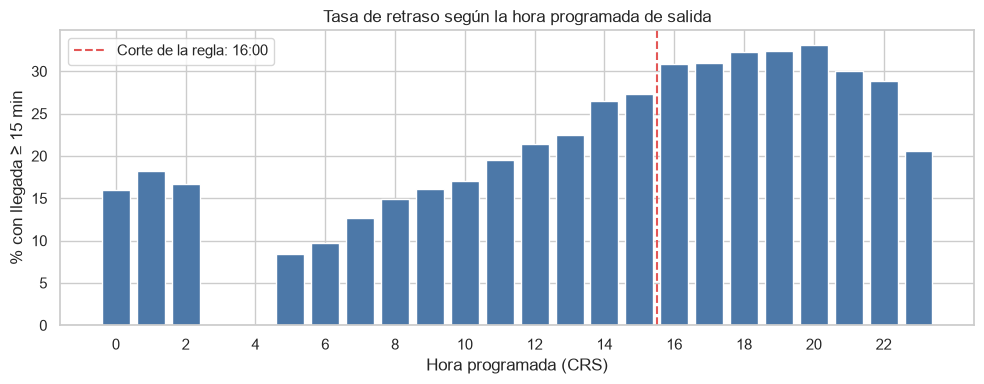

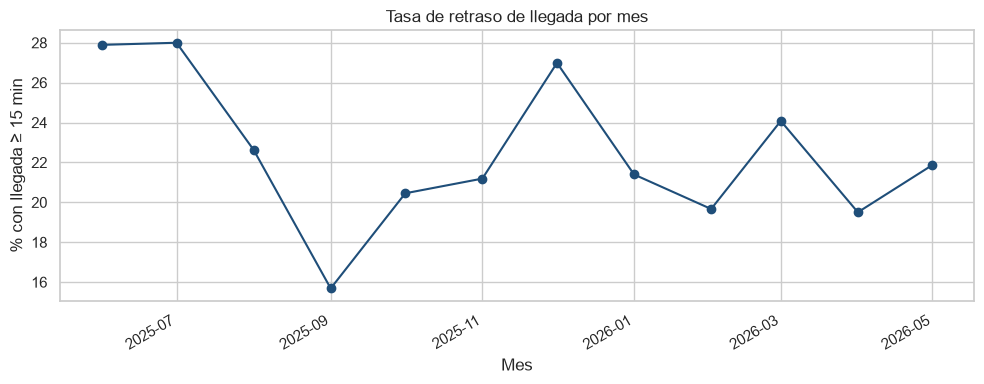

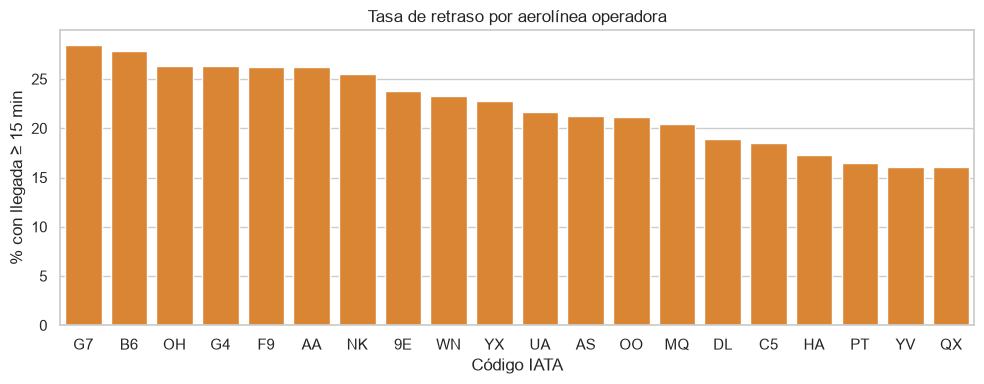

La tasa sube hacia la tarde: la regla de las 16:00 tiene base en los datos. También cambia por mes y por aerolínea, que la regla no usa.


In [6]:
from src.utils.plots import (
    plot_delay_rate_by_hour,
    plot_delay_rate_by_month,
    plot_delay_rate_by_carrier,
)

plot_delay_rate_by_hour(df_feat)
plt.show()
plot_delay_rate_by_month(df_feat)
plt.show()
plot_delay_rate_by_carrier(df_feat)
plt.show()
print(
    "La tasa sube hacia la tarde: la regla de las 16:00 tiene base en los datos. "
    "También cambia por mes y por aerolínea, que la regla no usa."
)


## 5. Modelos y validación

Un `train_test_split` aleatorio entrenaría con marzo de 2026 para predecir junio de 2025. Aquí el corte es temporal:

- **Entrenamiento:** los primeros 75 % de la muestra, ya ordenada por fecha (junio 2025 a febrero 2026).
- **Prueba:** los últimos 25 % (marzo a mayo 2026). Se reporta al final. No elige el modelo ni el umbral.
- **Validación cruzada:** `TimeSeriesSplit` de 3 pliegues dentro del entrenamiento, la misma para todos los modelos. Un K-fold aleatorio metería meses futuros en el entrenamiento.

Todos los modelos pasan por el mismo Pipeline. La línea base predice la clase mayoritaria. La regla manual no se entrena.

`class_weight='balanced'` (y `scale_pos_weight` en XGBoost) evita que el modelo se quede callado en «puntual». El umbral de probabilidad se elige en el último pliegue de validación, maximizando el F1 del retraso. El 0,50 de scikit-learn no es una decisión de negocio.

**Familias.** Regresión logística, árbol de decisión, random forest, gradient boosting y XGBoost. KNN y SVM de kernel no entran: con decenas de miles de filas y aeropuertos en one-hot, cada predicción recorre el entrenamiento. La frontera lineal ya está en la logística. Una red neuronal no cambia la familia respecto del boosting en este problema.

Si dos modelos quedan a menos de 0,01 de ROC-AUC en validación, se prefiere el más simple.


In [7]:
from src.models.experiment import temporal_split

feature_cols = DEFAULT_NUMERICAL_FEATURES + DEFAULT_CATEGORICAL_FEATURES
X = df_feat[feature_cols].copy()
y = df_feat[TARGET_COLUMN].copy()
X_train, X_test, y_train, y_test, split_idx = temporal_split(X, y, test_fraction=0.25)
fechas = pd.to_datetime(df_feat["FL_DATE"], errors="coerce")
print(f"Train {len(X_train):,} | {fechas.iloc[:split_idx].min().date()} → {fechas.iloc[:split_idx].max().date()}")
print(f"Test  {len(X_test):,} | {fechas.iloc[split_idx:].min().date()} → {fechas.iloc[split_idx:].max().date()}")
print(f"Retraso train {y_train.mean():.2%} | test {y_test.mean():.2%}")
print("Meses de prueba:", sorted(fechas.iloc[split_idx:].dt.to_period('M').astype(str).unique()))


Train 57,150 | 2025-06-01 → 2026-03-04
Test  19,051 | 2026-03-04 → 2026-05-31
Retraso train 22.70% | test 22.04%
Meses de prueba: ['2026-03', '2026-04', '2026-05']


In [8]:
from src.features.imputation import compare_numeric_imputers

imputacion = compare_numeric_imputers(
    X_train["CRS_ELAPSED_TIME"],
    X_train["OP_UNIQUE_CARRIER"],
    mask_rate=0.2,
    random_state=RANDOM_STATE,
)
print(imputacion.attrs["decision"])
imputacion


La mediana por aerolínea baja el error de 52.775 a 46.841 (11.2% menos) al esconder duración programada del entrenamiento. Esa imputación queda dentro del Pipeline, ajustada solo con cada pliegue. Una aerolínea que no estuvo en el entrenamiento usa la mediana global.


,metodo,mae,valores_escondidos
0,Mediana por aerolínea,46.841,11430
1,Mediana global,52.775,11430
2,Media global,54.374,11430


In [9]:
from src.models.experiment import compare_models, get_candidate_models

print("Modelos bajo la misma validación:")
for nombre in get_candidate_models(y_train):
    print(" -", nombre)

resultados, pipes = compare_models(X_train, X_test, y_train, y_test, quick=False)
columnas = [
    "modelo", "cv_roc_auc", "cv_roc_auc_std", "umbral",
    "f1_umbral_test", "precision_umbral_test", "recall_umbral_test",
    "roc_auc", "pr_auc", "accuracy", "segundos",
]
tabla = resultados[columnas].sort_values("cv_roc_auc", ascending=False)
tabla


Modelos bajo la misma validación:
 - Dummy (Línea Base)
 - Regresión Logística
 - Árbol de Decisión
 - Random Forest
 - Gradient Boosting
 - XGBoost


Entrenando Dummy (Línea Base)...
[2026-10-14 20:51:36] [INFO] [pipeline] ColumnTransformer configurado: 14 variables numéricas y 6 variables categóricas.


[2026-10-14 20:51:36] [INFO] [pipeline] ColumnTransformer configurado: 14 variables numéricas y 6 variables categóricas.


[2026-10-14 20:51:37] [INFO] [pipeline] ColumnTransformer configurado: 14 variables numéricas y 6 variables categóricas.


[2026-10-14 20:51:38] [INFO] [pipeline] ColumnTransformer configurado: 14 variables numéricas y 6 variables categóricas.


...

[2026-10-14 20:54:44] [INFO] [pipeline] ColumnTransformer configurado: 14 variables numéricas y 6 variables categóricas.


[2026-10-14 20:54:46] [INFO] [pipeline] ColumnTransformer configurado: 14 variables numéricas y 6 variables categóricas.


[2026-10-14 20:54:49] [INFO] [pipeline] ColumnTransformer configurado: 14 variables numéricas y 6 variables categóricas.


  CV ROC-AUC 0.6285 | umbral 0.4 | F1 test en ese umbral 0.4026 | 12.9 s


,modelo,cv_roc_auc,cv_roc_auc_std,umbral,f1_umbral_test,precision_umbral_test,recall_umbral_test,roc_auc,pr_auc,accuracy,segundos
6,XGBoost,0.6285,0.0299,0.4,0.4026,0.2661,0.8271,0.6374,0.3046,0.6040,12.9
5,Gradient Boosting,0.6273,0.0251,0.4,0.4038,0.2709,0.7923,0.6374,0.3065,0.6229,32.5
4,Random Forest,0.6259,0.0269,0.4,0.4037,0.2713,0.7880,0.6399,0.3080,0.6819,133.1
2,Regresión Logística,0.6193,0.0253,0.3,0.4070,0.2721,0.8073,0.6524,0.3246,0.7403,9.0
3,Árbol de Decisión,0.6107,0.0239,0.4,0.3956,0.2602,0.8244,0.6207,0.2876,0.5941,7.1
1,Dummy (Línea Base),0.5000,0.0000,0.5,0.0000,0.0000,0.0000,0.5000,0.2204,0.7796,3.7
0,Regla Manual (Hubs + Tarde),NaN,NaN,NaN,0.2796,0.3012,0.2608,NaN,NaN,0.7038,0.2


## 6. Evaluación

La columna `cv_roc_auc` es la que elige. `roc_auc` y `f1_umbral_test` son el reporte del tramo marzo–mayo 2026, con el umbral que ya se había fijado en validación.

La búsqueda de hiperparámetros también mira solo validación. Hace falta una ganancia de al menos 0,005 de ROC-AUC, en el mismo `TimeSeriesSplit`, para reemplazar la configuración base. Si no aparece, se deja el modelo simple.


In [10]:
from src.models.experiment import (
    apply_tuning_decision,
    choose_champion,
    explain_choice,
    tune_top_models,
)

campeon = choose_champion(resultados)
print("Campeón antes de ajustar hiperparámetros:", campeon)

busqueda = tune_top_models(resultados, X_train, y_train, champion=campeon, quick=False, n_iter=4)
busqueda.drop(columns=["estimador"])


Campeón antes de ajustar hiperparámetros: Regresión Logística
Buscando hiperparámetros de Regresión Logística...
[2026-10-14 20:54:55] [INFO] [pipeline] ColumnTransformer configurado: 14 variables numéricas y 6 variables categóricas.


[2026-10-14 20:54:57] [INFO] [pipeline] ColumnTransformer configurado: 14 variables numéricas y 6 variables categóricas.


[2026-10-14 20:54:59] [INFO] [pipeline] ColumnTransformer configurado: 14 variables numéricas y 6 variables categóricas.


  Misma validación: base 0.6030 -> ajustado 0.6031


Buscando hiperparámetros de XGBoost...
[2026-10-14 20:55:14] [INFO] [pipeline] ColumnTransformer configurado: 14 variables numéricas y 6 variables categóricas.


[2026-10-14 20:55:15] [INFO] [pipeline] ColumnTransformer configurado: 14 variables numéricas y 6 variables categóricas.


[2026-10-14 20:55:17] [INFO] [pipeline] ColumnTransformer configurado: 14 variables numéricas y 6 variables categóricas.


  Misma validación: base 0.6120 -> ajustado 0.6103


,modelo,cv_roc_auc_base,cv_roc_auc_ajustado,ganancia_cv,mejores_parametros,segundos
0,Regresión Logística,0.603,0.6031,0.0001,{'C': 3.8528572256396645},17.8
1,XGBoost,0.612,0.6103,-0.0017,"{'learning_rate': 0.1178392730173686, 'max_dep...",20.1


In [11]:
resultados, modelo_ajustado, campeon, nota_ajuste = apply_tuning_decision(
    resultados, busqueda, campeon, X_train, y_train, X_test, y_test
)
print(nota_ajuste)
print(explain_choice(resultados, campeon))
resultados[columnas].sort_values("cv_roc_auc", ascending=False)


El ajuste no cambia la decisión. En la misma validación temporal, Regresión Logística pasó de 0.6030 a 0.6031 (ganancia 0.0001); XGBoost pasó de 0.6120 a 0.6103 (ganancia -0.0017). Hace falta al menos 0.005 para reemplazar la configuración base, y ningún otro modelo superó al campeón por más de 0.01. Se conserva la configuración base.
Campeón por validación temporal: Regresión Logística. ROC-AUC de validación 0.6193 (desviación 0.0253). La línea base acierta el 77.96% de la prueba porque predice siempre puntual, con recall de retraso 0.00. En la prueba, con el umbral elegido en validación (0.3), el F1 del retraso es 0.4070 frente a 0.2796 de la regla manual. Supera la regla en el punto de operación, que es el número que había que vencer.


,modelo,cv_roc_auc,cv_roc_auc_std,umbral,f1_umbral_test,precision_umbral_test,recall_umbral_test,roc_auc,pr_auc,accuracy,segundos
6,XGBoost,0.6285,0.0299,0.4,0.4026,0.2661,0.8271,0.6374,0.3046,0.6040,12.9
5,Gradient Boosting,0.6273,0.0251,0.4,0.4038,0.2709,0.7923,0.6374,0.3065,0.6229,32.5
4,Random Forest,0.6259,0.0269,0.4,0.4037,0.2713,0.7880,0.6399,0.3080,0.6819,133.1
2,Regresión Logística,0.6193,0.0253,0.3,0.4070,0.2721,0.8073,0.6524,0.3246,0.7403,9.0
3,Árbol de Decisión,0.6107,0.0239,0.4,0.3956,0.2602,0.8244,0.6207,0.2876,0.5941,7.1
1,Dummy (Línea Base),0.5000,0.0000,0.5,0.0000,0.0000,0.0000,0.5000,0.2204,0.7796,3.7
0,Regla Manual (Hubs + Tarde),NaN,NaN,NaN,0.2796,0.3012,0.2608,NaN,NaN,0.7038,0.2


[2026-10-14 20:55:34] [INFO] [pipeline] ColumnTransformer configurado: 14 variables numéricas y 6 variables categóricas.


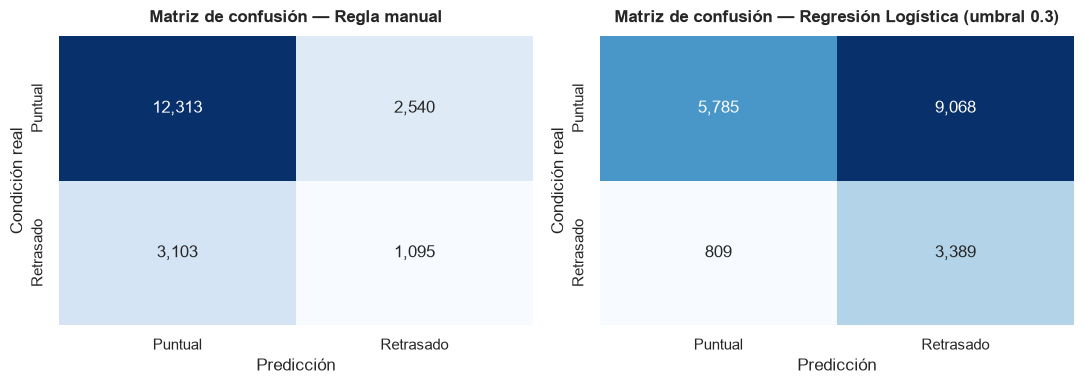

In [12]:
from sklearn.base import clone

from src.models.evaluate import plot_confusion_matrix
from src.models.experiment import get_candidate_models, regla_manual_prediccion
from src.models.pipeline import build_full_pipeline

fila = resultados.set_index("modelo").loc[campeon]
umbral = float(fila["umbral"]) if pd.notna(fila["umbral"]) else 0.5
if modelo_ajustado is not None:
    modelo_final = modelo_ajustado
else:
    modelo_final = build_full_pipeline(clone(get_candidate_models(y_train)[campeon]))
    modelo_final.fit(X_train, y_train)
proba = modelo_final.predict_proba(X_test)[:, 1]
pred_modelo = (proba >= umbral).astype(int)
pred_regla = regla_manual_prediccion(X_test)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
plot_confusion_matrix(y_test, pred_regla, "Regla manual", ax=axes[0])
plot_confusion_matrix(y_test, pred_modelo, f"{campeon} (umbral {umbral})", ax=axes[1])
plt.tight_layout()
plt.show()


In [13]:
import joblib

MODELS_DIR.mkdir(parents=True, exist_ok=True)
reporte = resultados.copy()
reporte.to_csv(MODELS_DIR / "metrics_comparison.csv", index=False)
busqueda.drop(columns=["estimador"], errors="ignore").to_csv(MODELS_DIR / "hiperparametros.csv", index=False)
joblib.dump(modelo_final, MODELS_DIR / "best_model.joblib")
texto = explain_choice(resultados, campeon)
(MODELS_DIR / "eleccion.txt").write_text(texto + chr(10) + chr(10) + nota_ajuste + chr(10), encoding="utf-8")
print("Guardado en models/metrics_comparison.csv, models/hiperparametros.csv y models/best_model.joblib")
print(texto)


Guardado en models/metrics_comparison.csv, models/hiperparametros.csv y models/best_model.joblib
Campeón por validación temporal: Regresión Logística. ROC-AUC de validación 0.6193 (desviación 0.0253). La línea base acierta el 77.96% de la prueba porque predice siempre puntual, con recall de retraso 0.00. En la prueba, con el umbral elegido en validación (0.3), el F1 del retraso es 0.4070 frente a 0.2796 de la regla manual. Supera la regla en el punto de operación, que es el número que había que vencer.


## Límites

El clima, el control de tráfico y el avión que llega tarde no están en el itinerario. Con solo datos previos al vuelo, el orden del riesgo queda lejos de un AUC perfecto.

La auditoría usa los 7.786.702 vuelos crudos. Los modelos usan el 1 % de los vuelos operados de cada mes, con semilla 42, de modo que el mes grande pesa más que el chico.
